# Capitolo 5 — Calibrazione della camera e stima della posa
Arcangelo Distante e Cosimo Distante — **Computer Vision**

Questo notebook usa esclusivamente segnali, punti e camere sintetici, definiti nel codice. Non contiene immagini esterne, benchmark, addestramento o misure di una camera reale. Le quantità calcolate illustrano i modelli e le loro condizioni di validità.

## Avvio e materiali
In Google Colab aprire questo file, selezionare un runtime **CPU** e avviare le celle dall’alto. Non servono GPU, file da caricare né download di dati. Sono necessarie NumPy e Matplotlib, normalmente già disponibili in Colab; in un ambiente nuovo installarle prima dell’esecuzione con `%pip install numpy matplotlib`. In locale è adeguato Python 3 con le stesse dipendenze.

La cartella `output_capitolo05` viene creata nello stesso runtime. Alla fine contiene figure, eventuali CSV e `metriche.json`. Per conservarla in Colab scaricarla dal pannello File prima di chiudere il runtime, oppure copiarla nel proprio Drive dopo averlo montato. Il riavvio elimina le variabili: rieseguire dalla prima cella. Per ogni esperimento modificato conservare parametri, seed e output in una nuova cartella.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

OUTPUT = Path('output_capitolo05')
OUTPUT.mkdir(exist_ok=True)
rng = np.random.default_rng(2026)
metriche = {}
plt.rcParams.update({'font.size': 10, 'figure.figsize': (7, 4)})

def salva_figura(nome):
    plt.tight_layout()
    plt.savefig(OUTPUT / (nome + '.png'), dpi=160)
    plt.show()
    plt.close()

def proietta(P, X):
    q = np.c_[X, np.ones(len(X))] @ P.T
    return q[:, :2] / q[:, 2:]


In [2]:
def applica_H(H, p):
    q = np.c_[p, np.ones(len(p))] @ H.T
    with np.errstate(divide='ignore', invalid='ignore'):
        return q[:, :2] / q[:, 2:]

def normalizza(p):
    centro = p.mean(axis=0)
    distanza = np.linalg.norm(p - centro, axis=1).mean()
    if distanza < 1e-12:
        raise ValueError('Configurazione priva di estensione')
    s = np.sqrt(2) / distanza
    T = np.array([[s, 0, -s*centro[0]], [0, s, -s*centro[1]], [0, 0, 1.]])
    return applica_H(T, p), T

def dlt(p, q):
    if len(p) < 4:
        raise ValueError('Servono almeno quattro corrispondenze')
    pn, T = normalizza(np.asarray(p, dtype=float))
    qn, U = normalizza(np.asarray(q, dtype=float))
    A = []
    for (x, y), (u, v) in zip(pn, qn):
        A.extend([[-x, -y, -1, 0, 0, 0, u*x, u*y, u],
                  [0, 0, 0, -x, -y, -1, v*x, v*y, v]])
    A = np.asarray(A)
    if np.linalg.matrix_rank(A) < 8:
        raise ValueError('Configurazione degenere')
    # full_matrices=True conserva la direzione nulla anche con una matrice 8x9.
    _, _, Vt = np.linalg.svd(A, full_matrices=True)
    H = np.linalg.inv(U) @ Vt[-1].reshape(3, 3) @ T
    return H / np.linalg.norm(H)
def rotazione(rx, ry, rz):
    cx, sx = np.cos(rx), np.sin(rx)
    cy, sy = np.cos(ry), np.sin(ry)
    cz, sz = np.cos(rz), np.sin(rz)
    Rx = np.array([[1, 0, 0], [0, cx, -sx], [0, sx, cx]])
    Ry = np.array([[cy, 0, sy], [0, 1, 0], [-sy, 0, cy]])
    Rz = np.array([[cz, -sz, 0], [sz, cz, 0], [0, 0, 1]])
    return Rz @ Ry @ Rx


## N5.A1 — Calibrazione planare ideale

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

K nota: [[800.   0. 320.]
 [  0. 820. 240.]
 [  0.   0.   1.]]
K stimata: [[8.00000000e+02 2.76862958e-13 3.20000000e+02]
 [0.00000000e+00 8.20000000e+02 2.40000000e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


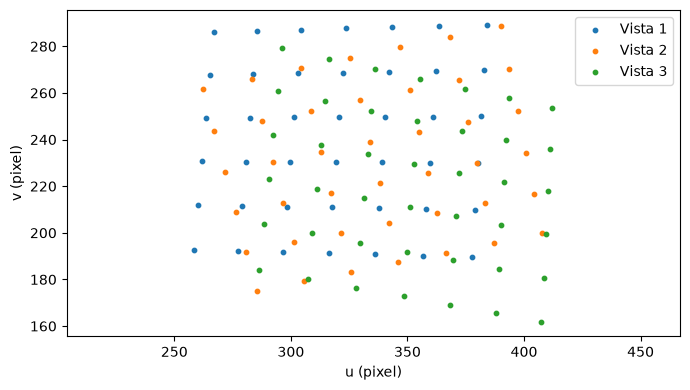

In [3]:
K_vera = np.array([[800., 0, 320], [0, 820., 240], [0, 0, 1.]])
xx, yy = np.meshgrid(np.linspace(-0.2,0.2,7), np.linspace(-0.15,0.15,6))
target = np.c_[xx.ravel(), yy.ravel()]
angoli = [(0.2,0.4,0), (-0.4,0.1,0.2), (0.35,-0.3,-0.2)]
def v_ij(H, i, j):
    h, g = H[:,i], H[:,j]
    return np.array([h[0]*g[0], h[0]*g[1]+h[1]*g[0], h[1]*g[1],
                     h[2]*g[0]+h[0]*g[2], h[2]*g[1]+h[1]*g[2], h[2]*g[2]])
V = []
for i, ang in enumerate(angoli):
    R = rotazione(*ang)
    H_nota = K_vera @ np.c_[R[:,:2], np.array([0.05*i, -0.03*i, 2.5])]
    osservazioni = applica_H(H_nota, target)
    H = dlt(target, osservazioni)
    V.extend([v_ij(H,0,1), v_ij(H,0,0)-v_ij(H,1,1)])
    plt.scatter(*osservazioni.T, s=10, label=f'Vista {i+1}')
_, singolari, Vt = np.linalg.svd(np.asarray(V))
b = Vt[-1]
B = np.array([[b[0],b[1],b[3]], [b[1],b[2],b[4]], [b[3],b[4],b[5]]])
if B[2,2] < 0:
    B = -B
L = np.linalg.cholesky(B)
K_stimata = np.linalg.inv(L.T)
K_stimata /= K_stimata[2,2]
metriche['errore_massimo_K_pixel'] = float(np.max(np.abs(K_stimata-K_vera)))
metriche['valori_singolari_calibrazione'] = singolari.tolist()
print('K nota:', K_vera)
print('K stimata:', K_stimata)
plt.xlabel('u (pixel)'); plt.ylabel('v (pixel)'); plt.legend(); plt.axis('equal')
salva_figura('A1_viste_calibrazione')


**Domande**

1. Collegare i due vincoli di ogni vista all’ortonormalità della rotazione.
2. Sostituire le pose con viste frontoparallele e discutere il rango del sistema e l’eventuale fallimento della Cholesky.

## N5.A2 — Distorsione e inversione numerica

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

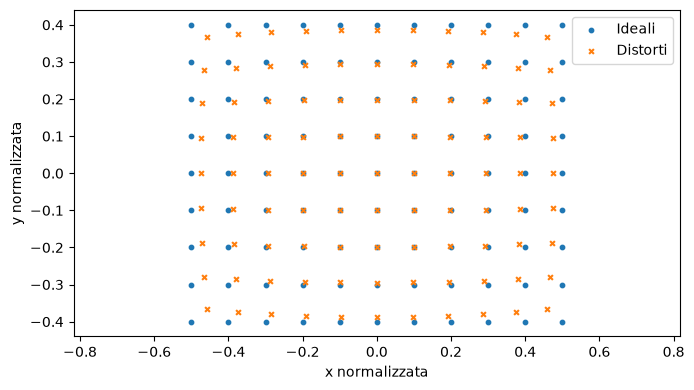

Errore inverso: 7.850462293418876e-17


In [4]:
xx, yy = np.meshgrid(np.linspace(-0.5,0.5,11), np.linspace(-0.4,0.4,9))
ideali = np.c_[xx.ravel(), yy.ravel()]
k1 = -0.2
r2 = np.sum(ideali**2, axis=1)
distorti = ideali*(1+k1*r2)[:,None]
recuperati = distorti.copy()
for _ in range(30):
    r2_stima = np.sum(recuperati**2, axis=1)
    recuperati = distorti/(1+k1*r2_stima)[:,None]
metriche['errore_inversione_normalizzato'] = float(np.max(np.linalg.norm(recuperati-ideali,axis=1)))
plt.scatter(*ideali.T, s=10, label='Ideali')
plt.scatter(*distorti.T, s=12, marker='x', label='Distorti')
plt.xlabel('x normalizzata'); plt.ylabel('y normalizzata'); plt.axis('equal'); plt.legend()
salva_figura('A2_distorsione')
print('Errore inverso:', metriche['errore_inversione_normalizzato'])


**Domande**

1. Interpretare il segno del coefficiente nel modello diretto adottato.
2. Perché l’accordo diretto/inverso con parametri noti non valida la loro stima sperimentale?

## N5.A3 — Sistemi di riferimento e centro camera

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

In [5]:
R = rotazione(0.15, -0.2, 0.3)
t = np.array([0.1, -0.05, 2.])
C = -R.T @ t
X_mondo = np.array([[0.,0.,0.], [0.2,0.,0.], [0.,0.2,0.1]])
X_camera = X_mondo @ R.T + t
X_ricostruiti = (X_camera-t) @ R
metriche['errore_inversione_posa_m'] = float(np.max(np.abs(X_ricostruiti-X_mondo)))
metriche['centro_camera_mondo_m'] = C.tolist()
metriche['norma_centro_nel_frame_camera_m'] = float(np.linalg.norm(R@C+t))
metriche['profondita_minima_m'] = float(X_camera[:,2].min())
print('Centro nel mondo:', C)
print('Centro trasformato nella camera:', R@C+t)
np.savetxt(OUTPUT/'A3_punti_camera.csv', X_camera, delimiter=',', header='X_m,Y_m,Z_m', comments='')


Centro nel mondo: [-0.47648652 -0.21407041 -1.93381345]
Centro trasformato nella camera: [-2.77555756e-17 -1.38777878e-17  2.22044605e-16]


**Domande**

1. Derivare la trasformazione inversa e interpretare C e t.
2. Verificare le profondità e discutere perché la cheiralità è un controllo distinto dalla riproiezione.

## Conservare i risultati

La cella seguente salva le quantità calcolate durante questa esecuzione. I valori del file descrivono questi dati sintetici e questi parametri. Non rappresentano prestazioni su dati reali.

In [6]:
with (OUTPUT / 'metriche.json').open('w') as f_json:
    json.dump(metriche, f_json, indent=2, allow_nan=False)
print('Output salvati in:', OUTPUT)

Output salvati in: output_capitolo05
